In [1]:
# Dimensionality Reduction - PCA and t-SNE
# Datasets (both built into sklearn):
#   - digits: an 8x8 pixel version of MNIST, good for quick practice
#   - wine: 13 chemical features of wine samples
#
# Note: if you specifically want the full-size 28x28 MNIST from Kaggle,
# swap the digits-loading section for pd.read_csv() on that file instead -
# the PCA/t-SNE code below works the same either way.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits, load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

(178, 14)
   alcohol  malic_acid   ash  alcalinity_of_ash  magnesium  total_phenols  \
0    14.23        1.71  2.43               15.6      127.0           2.80   
1    13.20        1.78  2.14               11.2      100.0           2.65   
2    13.16        2.36  2.67               18.6      101.0           2.80   
3    14.37        1.95  2.50               16.8      113.0           3.85   
4    13.24        2.59  2.87               21.0      118.0           2.80   

   flavanoids  nonflavanoid_phenols  proanthocyanins  color_intensity   hue  \
0        3.06                  0.28             2.29             5.64  1.04   
1        2.76                  0.26             1.28             4.38  1.05   
2        3.24                  0.30             2.81             5.68  1.03   
3        3.49                  0.24             2.18             7.80  0.86   
4        2.69                  0.39             1.82             4.32  1.04   

   od280/od315_of_diluted_wines  proline  target  
0

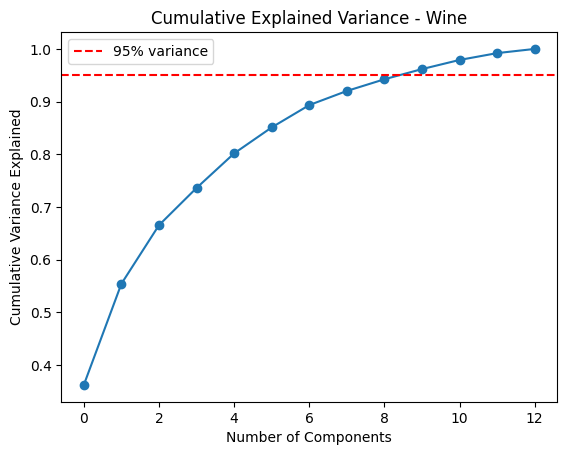

Variance explained by 2 components: 0.5540633835693526


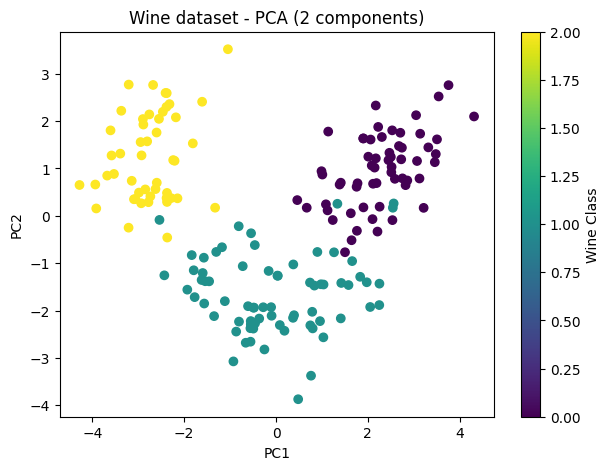

In [2]:
# ============================================================
# PART 1 - Wine dataset (13 features -> reduce to 2)
# ============================================================

wine = load_wine()
wine_df = pd.DataFrame(wine.data, columns=wine.feature_names)
wine_df["target"] = wine.target

print(wine_df.shape)
print(wine_df.head())

X_wine = wine_df.drop(columns=["target"])
y_wine = wine_df["target"]

# ---- 1. Scale first - PCA is sensitive to feature scale ----
scaler = StandardScaler()
X_wine_scaled = scaler.fit_transform(X_wine)

# ---- 2. Check how much variance each component explains ----
pca_full = PCA()
pca_full.fit(X_wine_scaled)

plt.plot(np.cumsum(pca_full.explained_variance_ratio_), marker="o")
plt.title("Cumulative Explained Variance - Wine")
plt.xlabel("Number of Components")
plt.ylabel("Cumulative Variance Explained")
plt.axhline(y=0.95, color="r", linestyle="--", label="95% variance")
plt.legend()
plt.show()

# usually ~8-10 components explain 95% of variance - much less than the original 13

# ---- 3. Reduce to 2 components for visualization ----
pca_2d = PCA(n_components=2)
X_wine_pca = pca_2d.fit_transform(X_wine_scaled)

print("Variance explained by 2 components:", sum(pca_2d.explained_variance_ratio_))

plt.figure(figsize=(7, 5))
plt.scatter(X_wine_pca[:, 0], X_wine_pca[:, 1], c=y_wine, cmap="viridis")
plt.title("Wine dataset - PCA (2 components)")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.colorbar(label="Wine Class")
plt.show()

# the 3 wine classes separate pretty well even with just 2 components

(1797, 64)


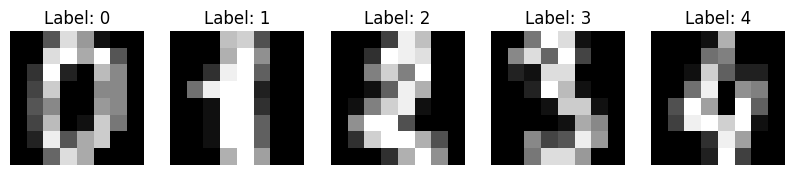

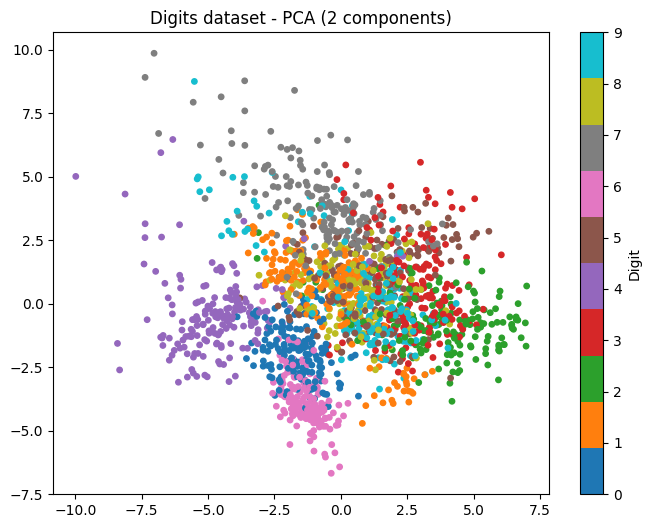

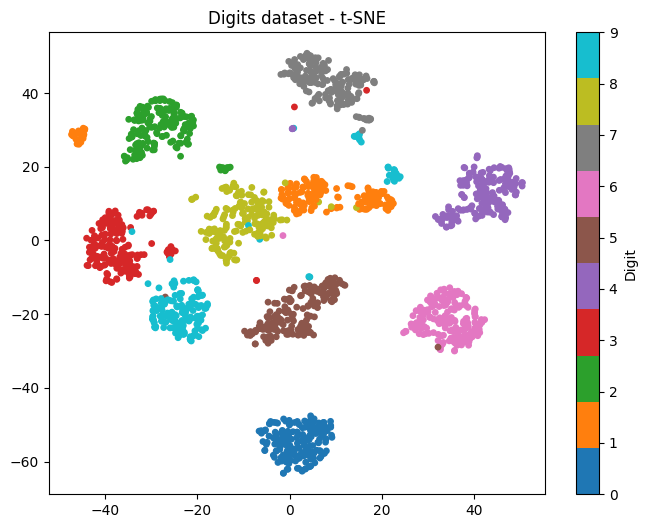

In [3]:
# ============================================================
# PART 2 - Digits dataset (8x8 images, MNIST-style, 64 features -> 2)
# ============================================================

digits = load_digits()
X_digits = digits.data      # 64 features (8x8 pixels flattened)
y_digits = digits.target    # digit labels 0-9

print(X_digits.shape)

# ---- 4. Look at a few actual digit images first ----
fig, axes = plt.subplots(1, 5, figsize=(10, 2))
for i, ax in enumerate(axes):
    ax.imshow(digits.images[i], cmap="gray")
    ax.set_title(f"Label: {digits.target[i]}")
    ax.axis("off")
plt.show()

# ---- 5. PCA on digits ----
X_digits_scaled = StandardScaler().fit_transform(X_digits)

pca_digits = PCA(n_components=2)
X_digits_pca = pca_digits.fit_transform(X_digits_scaled)

plt.figure(figsize=(8, 6))
scatter = plt.scatter(X_digits_pca[:, 0], X_digits_pca[:, 1], c=y_digits, cmap="tab10", s=15)
plt.title("Digits dataset - PCA (2 components)")
plt.colorbar(scatter, label="Digit")
plt.show()

# PCA gives some separation but digits overlap quite a bit in just 2D

# ---- 6. t-SNE on digits (usually much better visual separation than PCA) ----
# t-SNE is slower and only really meant for visualization, not general dim reduction
tsne = TSNE(n_components=2, random_state=42, perplexity=30)
X_digits_tsne = tsne.fit_transform(X_digits)

plt.figure(figsize=(8, 6))
scatter = plt.scatter(X_digits_tsne[:, 0], X_digits_tsne[:, 1], c=y_digits, cmap="tab10", s=15)
plt.title("Digits dataset - t-SNE")
plt.colorbar(scatter, label="Digit")
plt.show()

# t-SNE usually shows much cleaner, separated clusters per digit compared to PCA